This is an exploratory notebook for reading the data in this folder:
\\cryo-em\SURFACTANTE\RAW_DATA\TOMOS\Position_5\Processed

## Archivos de `Processed/` (Position_5)

Convenciones de IMOD. Deducido por los nombres, pendiente de confirmar con quien procesó los datos.

| Archivo | Qué es |
|---|---|
| `Position_5_MC.mrc` | Tilt series con corrección de movimiento (*MC*): un stack con una imagen por ángulo. |
| `Position_5_MC.rawtlt` | Ángulos de inclinación tal cual salieron del microscopio, uno por línea. |
| `Position_5_MC.tlt` | Ángulos finales, ya refinados tras el alineamiento. |
| `Position_5_MC_order_list.csv` | Orden en que se tomaron las imágenes (no se hicieron de menor a mayor ángulo). |
| `Position_5_MC.xf` | Transformaciones (desplazamiento, rotación) para alinear cada imagen con las demás. |
| `Position_5_MC.tltxf` | Las mismas transformaciones, ajustadas junto a los ángulos de inclinación. |
| `newst.com` | Receta de IMOD que aplica esas transformaciones y genera el stack alineado. |
| `Position_5_MC_ali.mrc` | Tilt series alineado, a resolución completa. |
| `Position_5_MC_bin4.mrc`, `_bin4_ali.mrc` | Las mismas imágenes reducidas 4×, sin alinear y alineadas. Sirven para trabajar rápido. |
| `Position_5_MC.defocus` | Desenfoque estimado por imagen (CTF), para corregir la distorsión del microscopio. |
| `tilt.com` | Receta de IMOD para reconstruir el tomograma. |
| `Position_5_SIRT_rec.mrc` | **Tomograma 3D**, reconstruido con SIRT. Es el único volumen real de la lista. |
| `Position_5_preview.mrc` | Vista previa pequeña (~2 MB), probablemente una reconstrucción reducida. |
| `reconstruction.json`, `tilt-series.json` | Metadatos del procesado y de la serie, escritos por la herramienta que lo hizo. |

**Flujo:** películas `.eer` (`Raw/`) → corrección de movimiento (`_MC`) → alineamiento con los ángulos (`.tlt`, `.xf`) → `_ali` → estimación de CTF (`.defocus`) → reconstrucción (`tilt.com`) → `SIRT_rec.mrc`.

**Ojo:** solo `SIRT_rec.mrc` es un volumen. En `_MC.mrc` y `_ali.mrc` el eje `z` es el ángulo de inclinación, no la profundidad.

# 1. Interpretación general de la carpeta

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mrcfile

BASE = Path(r"../datos/Processed")
POS = "Position_5"          # prefijo de los archivos

assert BASE.exists(), f"No existe {BASE}"
print("Carpeta:", BASE)

Carpeta: ..\datos\Processed


In [2]:
#Inventariado de archivos:
rows = [(f.name, f.suffix, round(f.stat().st_size / 1e6, 2)) for f in sorted(BASE.iterdir()) if f.is_file()]
inv = pd.DataFrame(rows, columns=["archivo", "extensión", "MB"])
inv

,archivo,extensión,MB
0,newst.com,.com,0.00
1,Position_5_MC.defocus,.defocus,0.00
2,Position_5_MC.mrc,.mrc,1308.66
3,Position_5_MC.rawtlt,.rawtlt,0.00
4,Position_5_MC.tlt,.tlt,0.00
5,Position_5_MC.tltxf,.tltxf,0.00
6,Position_5_MC.xf,.xf,0.00
7,Position_5_MC_ali.mrc,.mrc,1308.65
8,Position_5_MC_bin4.mrc,.mrc,81.82
9,Position_5_MC_bin4_ali.mrc,.mrc,81.82


In [3]:
def read_numbers(path):
    return np.loadtxt(path)

def first_lines(path, n=15):
    with open(path, errors="replace") as fh:
        for i, line in enumerate(fh):
            if i >= n: print("..."); break
            print(line.rstrip())

# .rawtlt (microscopio) vs .tlt (tras alineamiento)
raw = read_numbers(BASE / f"{POS}_MC.rawtlt") if (BASE / f"{POS}_MC.rawtlt").exists() else None
tlt = read_numbers(BASE / f"{POS}_MC.tlt") if (BASE / f"{POS}_MC.tlt").exists() else None
print("rawtlt:", None if raw is None else (len(raw), raw.min(), raw.max()))
print("tlt   :", None if tlt is None else (len(tlt), tlt.min(), tlt.max()))

rawtlt: (39, np.float64(-55.0), np.float64(55.0))
tlt   : (39, np.float64(-53.47), np.float64(56.53))


,1,1.53
0,2,4.53
1,3,7.53
2,4,-1.47
3,5,-4.47
4,6,-7.47
5,7,10.53
6,8,13.53
7,9,16.53
8,10,-10.47
9,11,-13.47


(38, 2)


,1,1.53
0,2,4.53
1,3,7.53
2,4,-1.47
3,5,-4.47
4,6,-7.47
5,7,10.53
6,8,13.53
7,9,16.53
8,10,-10.47
9,11,-13.47


(38, 2)


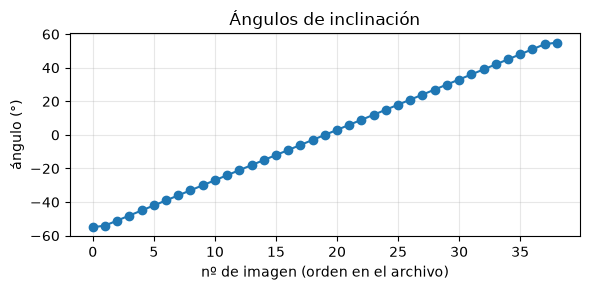

In [4]:
order_file = BASE / f"{POS}_MC_order_list.csv"
if order_file.exists():
    order = pd.read_csv(order_file)
    display(order.head(10))
    print(order.shape)
    
order_file = BASE / f"{POS}_MC_order_list.csv"
if order_file.exists():
    order = pd.read_csv(order_file)
    display(order.head(10))
    print(order.shape)
    
if raw is not None:
    plt.figure(figsize=(6, 3))
    plt.plot(raw, "o-")
    plt.xlabel("nº de imagen (orden en el archivo)"); plt.ylabel("ángulo (°)")
    plt.title("Ángulos de inclinación"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Se aprecia que no ha habido descarte de imágenes y que se aumenta la inclinación de forma gradual

xf shape: (39, 6) | desplazamientos dx, dy en píxeles:


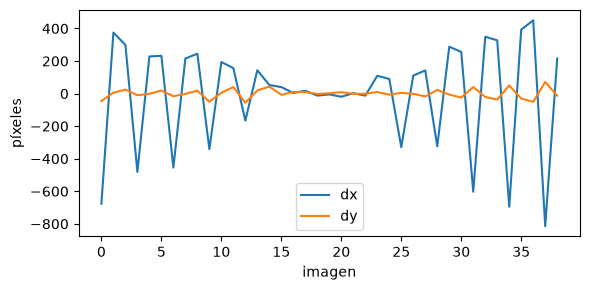


--- .defocus (primeras líneas) ---
1	0	0.0	0.0	0.0	3
1 1 -53.4728962848926 -53.4728962848926 3591.337425303182 3568.992050242147 45.0
2 2 -52.472032580807 -52.472032580807 3557.9759370179013 3535.630561956866 45.0
3 3 -49.4733453737831 -49.4733453737831 3454.0541774658923 3431.708802404857 45.0
4 4 -46.47270621414274 -46.47270621414274 3481.466026848867 3459.120651787832 45.0
5 5 -43.472555042656495 -43.472555042656495 3456.3333432385316 3433.9879681774964 45.0
6 6 -40.47240387117024 -40.47240387117024 3455.7721326398237 3433.4267575787885 45.0
7 7 -37.473228675992225 -37.473228675992225 3454.5383518967296 3432.1929768356945 45.0
...


In [5]:
# .xf: una fila por imagen, 6 números = matriz 2x2 + desplazamiento dx, dy
xf_file = BASE / f"{POS}_MC.xf"
if xf_file.exists():
    xf = read_numbers(xf_file)
    print("xf shape:", xf.shape, "| desplazamientos dx, dy en píxeles:")
    plt.figure(figsize=(6, 3)); plt.plot(xf[:, 4], label="dx"); plt.plot(xf[:, 5], label="dy")
    plt.legend(); plt.xlabel("imagen"); plt.ylabel("píxeles"); plt.tight_layout(); plt.show()

print("\n--- .defocus (primeras líneas) ---")
if (BASE / f"{POS}_MC.defocus").exists():
    first_lines(BASE / f"{POS}_MC.defocus", 8)

In [6]:
for name in ["newst.com", "tilt.com"]:
    p = BASE / name
    if p.exists():
        print(f"\n===== {name} =====")
        first_lines(p, 40)

p = BASE / "tilt-series.json"
if p.exists():
    d = json.loads(p.read_text())
    print("\n===== tilt-series.json =====")
    print("campos:", list(d.keys()) if isinstance(d, dict) else type(d))
    print(json.dumps(d, indent=2)[:1500])


===== newst.com =====

$setenv IMOD_OUTPUT_FORMAT MRC
$newstack -StandardInput
Inputfile  Position_5_MC.mrc
OutputFile  Position_5_MC_ali.mrc
TransformFile  Position_5_MC.xf
SizeToOutputInXandY  4096,4096
BinByFactor  1

===== tilt.com =====

$setenv IMOD_OUTPUT_FORMAT MRC
$tilt -StandardInput
InputProjections  Position_5_MC_ali.mrc
FULLIMAGE  4096 4096
TILTFILE  Position_5_MC.tlt
THICKNESS  928
IMAGEBINNED  1
SHIFT  0 -16

===== tilt-series.json =====
campos: <class 'list'>
[
  {
    "displayName": "Tilt Angle Total Mean Drift",
    "name": "application.tqm.tilt-angle-total-mean-drift",
    "value": "[{\"x\":-0.959940733,\"y\":24.81893},{\"x\":-0.9424723660000001,\"y\":18.90302},{\"x\":-0.8901354010000001,\"y\":17.96613},{\"x\":-0.8377643680000001,\"y\":24.22074},{\"x\":-0.7854018520000001,\"y\":17.88066},{\"x\":-0.733039336,\"y\":17.4989},{\"x\":-0.680693854,\"y\":23.12043},{\"x\":-0.6283143040000001,\"y\":4.06715},{\"x\":-0.5759603050000001,\"y\":4.11028},{\"x\":-0.5236063060000001

In [7]:
p = BASE / "reconstruction.json"
d = json.loads(p.read_text())

print("elementos en la lista:", len(d))
print("tipo del primero:", type(d[0]))

if isinstance(d[0], dict):
    print("campos del primer elemento:", list(d[0].keys()))
    print(json.dumps(d[0], indent=2)[:2000])
else:
    print(d[0])

elementos en la lista: 39
tipo del primero: <class 'dict'>
campos del primer elemento: ['displayName', 'name', 'value', 'dataType']
{
  "displayName": "Acquisition Order",
  "name": "application.qm.acquisition-order",
  "value": "13",
  "dataType": "integer"
}


In [8]:
info = []
for f in sorted(BASE.glob("*.mrc")):
    with mrcfile.mmap(f, permissive=True) as m:
        v = m.voxel_size
        info.append(dict(archivo=f.name, shape=tuple(m.data.shape), dtype=str(m.data.dtype),
                         voxel_A=round(float(v.x), 3), MB=round(f.stat().st_size / 1e6, 1)))
pd.DataFrame(info)

,archivo,shape,dtype,voxel_A,MB
0,Position_5_MC.mrc,"(39, 4096, 4096)",uint16,2.792,1308.7
1,Position_5_MC_ali.mrc,"(39, 4096, 4096)",uint16,2.792,1308.7
2,Position_5_MC_bin4.mrc,"(39, 1024, 1024)",uint16,11.166,81.8
3,Position_5_MC_bin4_ali.mrc,"(39, 1024, 1024)",uint16,11.166,81.8
4,Position_5_preview.mrc,"(1024, 1024)",uint16,0.000,2.1
5,Position_5_SIRT_rec.mrc,"(232, 1024, 1024)",int16,11.166,486.7


Usando: Position_5_MC_bin4_ali.mrc
shape: (39, 1024, 1024) | dtype: uint16


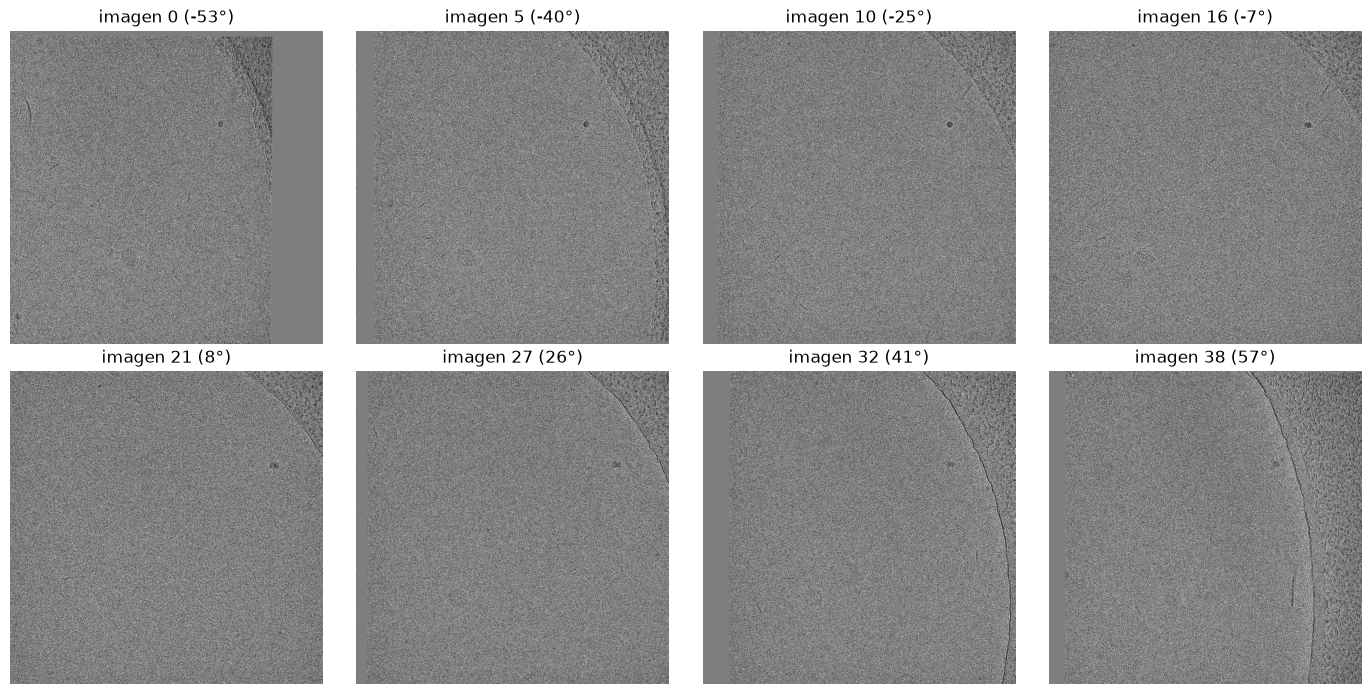

In [9]:
TS = BASE / f"{POS}_MC_bin4_ali.mrc"        # bin4 = rápido; cambia a _ali.mrc para resolución completa
if not TS.exists():
    TS = BASE / f"{POS}_MC_bin4.mrc"
print("Usando:", TS.name)

ts = mrcfile.mmap(TS, permissive=True)
data = ts.data
print("shape:", data.shape, "| dtype:", data.dtype)

sample = np.asarray(data[:: max(1, data.shape[0] // 8)], dtype=np.float32)
vmin, vmax = np.percentile(sample, (1, 99))

angles = tlt if (tlt is not None and len(tlt) == data.shape[0]) else None

idx = np.linspace(0, data.shape[0] - 1, min(8, data.shape[0])).astype(int)
fig, axs = plt.subplots(2, 4, figsize=(14, 7)); axs = axs.ravel()
for a, i in zip(axs, idx):
    a.imshow(data[i], cmap="gray", vmin=vmin, vmax=vmax); a.axis("off")
    a.set_title(f"imagen {i}" + (f" ({angles[i]:.0f}°)" if angles is not None else ""))
plt.tight_layout(); plt.show()

In [10]:
import ipywidgets as w

def show(i=0):
    plt.figure(figsize=(6, 6))
    plt.imshow(data[i], cmap="gray", vmin=vmin, vmax=vmax); plt.axis("off")
    plt.title(f"imagen {i}" + (f" - {angles[i]:.1f}°" if angles is not None else ""))
    plt.show()

w.interact(show, i=w.IntSlider(min=0, max=data.shape[0] - 1, step=1, value=0, continuous_update=False))

interactive(children=(IntSlider(value=0, continuous_update=False, description='i', max=38), Output()), _dom_cl…

<function __main__.show(i=0)>

shape: (232, 1024, 1024) | vóxel (Å): 11.166075706481934


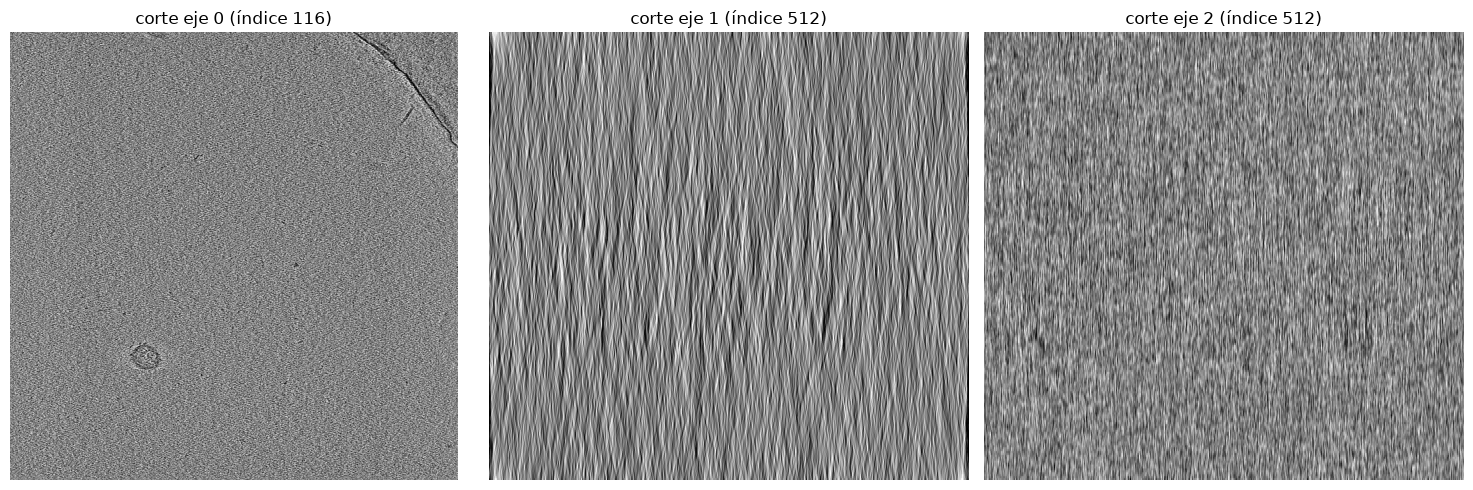

In [11]:
REC = BASE / f"{POS}_SIRT_rec.mrc"
rec = mrcfile.mmap(REC, permissive=True)
vol = rec.data
print("shape:", vol.shape, "| vóxel (Å):", float(rec.voxel_size.x))

sub = np.asarray(vol[:: max(1, vol.shape[0] // 8), :: 4, :: 4], dtype=np.float32)
lo, hi = np.percentile(sub, (1, 99))
z, y, x = (s // 2 for s in vol.shape)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(vol[z], cmap="gray", vmin=lo, vmax=hi); axs[0].set_title(f"corte eje 0 (índice {z})")
axs[1].imshow(vol[:, y, :], cmap="gray", vmin=lo, vmax=hi, aspect="auto"); axs[1].set_title(f"corte eje 1 (índice {y})")
axs[2].imshow(vol[:, :, x], cmap="gray", vmin=lo, vmax=hi, aspect="auto"); axs[2].set_title(f"corte eje 2 (índice {x})")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

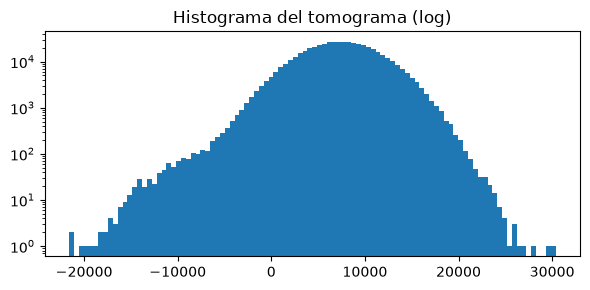

In [12]:
plt.figure(figsize=(6, 3)); plt.hist(sub.ravel(), bins=100, log=True)
plt.title("Histograma del tomograma (log)"); plt.tight_layout(); plt.show()

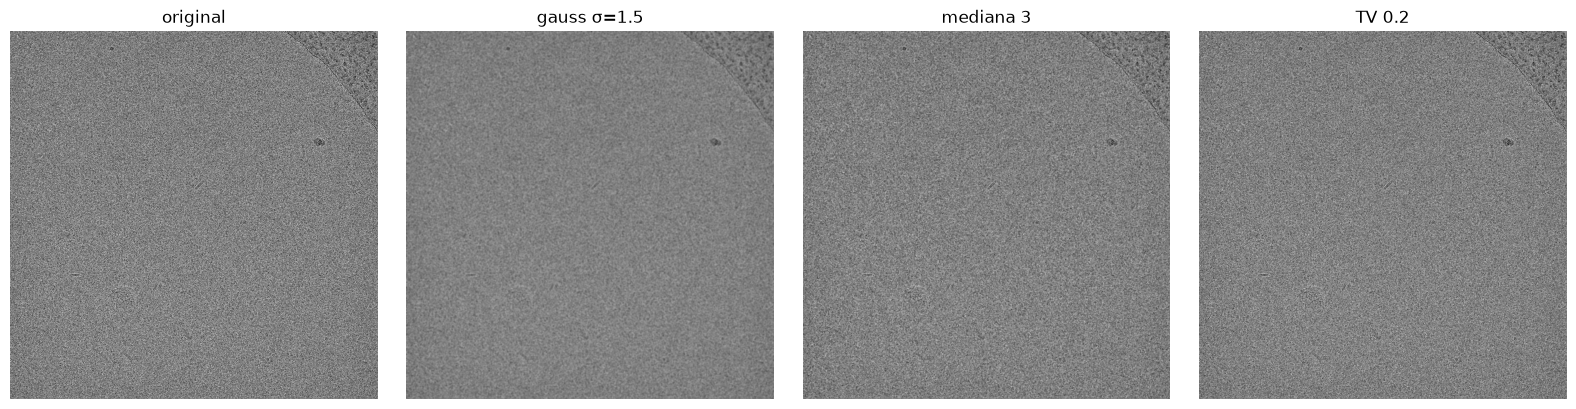

In [13]:
from scipy import ndimage as ndi
from skimage.restoration import denoise_tv_chambolle

i = data.shape[0] // 2
img = np.asarray(data[i], dtype=np.float32)
img = (img - img.mean()) / img.std()

res = {
    "original": img,
    "gauss σ=1.5": ndi.gaussian_filter(img, 1.5),
    "mediana 3": ndi.median_filter(img, 3),
    "TV 0.2": denoise_tv_chambolle(img, weight=0.2),
}
fig, axs = plt.subplots(1, len(res), figsize=(4 * len(res), 4))
for a, (k, im) in zip(axs, res.items()):
    a.imshow(im, cmap="gray", vmin=-2.5, vmax=2.5); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.show()

In [14]:
# %gui qt        # descomenta si la ventana no aparece
import napari

viewer = napari.Viewer(ndisplay=3)

# Tomograma en 3D
lo, hi = np.percentile(np.asarray(vol[::4, ::4, ::4], dtype=np.float32), (1, 99))
viewer.add_image(np.asarray(vol), name="tomograma", contrast_limits=(lo, hi),
                 colormap="gray", rendering="attenuated_mip")

# Tilt series (cada corte = un ángulo), oculto al principio
viewer.add_image(np.asarray(data), name="tilt series (bin4 ali)", colormap="gray",
                 contrast_limits=(vmin, vmax), visible=False)

napari.run()

# 2. Procesado de las imágenes

In [15]:
# %gui qt        # descomenta si la ventana no aparece
import napari
from scipy import ndimage as ndi

vol_np = np.asarray(vol, dtype=np.float32)
vol_f = ndi.gaussian_filter(vol_np, sigma=2)        # puede tardar un poco

lo, hi = np.percentile(vol_np[::4, ::4, ::4], (1, 99))
lo_f, hi_f = np.percentile(vol_f[::4, ::4, ::4], (1, 99))

viewer = napari.Viewer(ndisplay=2)       # empieza en 2D para comparar cortes

viewer.add_image(vol_np, name="original", contrast_limits=(lo, hi), colormap="gray")
viewer.add_image(vol_f, name="gauss σ=2", contrast_limits=(lo_f, hi_f), colormap="gray")

napari.run()